# Clinic no-shows: working notebook

Reads what `python run_pipeline.py` produced (`data/raw`, `data/processed/clinic.db`, `outputs/`). Run the pipeline first.

Sections: 1 retrieval evidence, 2 profiling the raw file, 3 validation, 4 the model and SQL joins,
5 metrics and the SMS judgement call, 6 what is still unknown.

In [1]:
import json, sqlite3, sys
from pathlib import Path
import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "scripts"))
import common as c, rules
con = sqlite3.connect(c.DB_PATH)
pd.set_option("display.width", 160)

## 1. Retrieval: what was fetched and how I know it is complete

Two source types: a CSV file over HTTPS (the appointment extract) and two JSON APIs (public holidays, daily weather).
The CSV is only accepted if its sha256 matches the pinned value, and its row count must be 110,527.

In [2]:
m = json.loads((ROOT / "outputs" / "raw_manifest.json").read_text())
pd.DataFrame(m).T[["url", "sha256", "rows", "records", "size_bytes"]]

,url,sha256,rows,records,size_bytes
appointments,https://raw.githubusercontent.com/alteryx/pred...,9132d3e7d0246617df9041d3764f20ad6f08e7b0d9f099...,110527,NaN,10739535
holidays,https://date.nager.at/api/v3/PublicHolidays/20...,567f7776fbd3873428a0fed9c14f8a62003470be4d79c3...,NaN,14,NaN
weather,https://archive-api.open-meteo.com/v1/archive?...,03723002d1e106b580c7deff18220a1c14e98731c83698...,NaN,41,NaN


## 2. Profiling the raw file (before any rule)

In [3]:
raw = pd.read_csv(c.APPTS_CSV, dtype={"PatientId": str})
print(raw.shape, "| nulls:", int(raw.isna().sum().sum()))
raw.head(3)

(110527, 14) | nulls: 0


,PatientId,AppointmentID,Gender,ScheduledDay,AppointmentDay,Age,Neighbourhood,Scholarship,Hipertension,Diabetes,Alcoholism,Handcap,SMS_received,No-show
0,29872499824296,5642903,F,2016-04-29T18:38:08Z,2016-04-29T00:00:00Z,62,JARDIM DA PENHA,0,1,0,0,0,0,No
1,558997776694438,5642503,M,2016-04-29T16:08:27Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,0,0,0,0,0,No
2,4262962299951,5642549,F,2016-04-29T16:19:04Z,2016-04-29T00:00:00Z,62,MATA DA PRAIA,0,0,0,0,0,0,No


In [4]:
d = rules.add_derived(raw)
profile = {
    "appointments": len(d),
    "patients": d["PatientId"].nunique(),
    "appointment dates": f"{d['appointment_date'].min().date()} .. {d['appointment_date'].max().date()}",
    "booking dates": f"{d['booked_ts'].min().date()} .. {d['booked_ts'].max().date()}",
    "appointment time of day always 00:00": bool((d["appointment_date"].dt.hour == 0).all()),
    "booking hours seen": f"{d['booked_ts'].dt.hour.min()}-{d['booked_ts'].dt.hour.max()} (peak {d['booked_ts'].dt.hour.mode()[0]}h)",
    "age min / max": f"{d['Age'].min()} / {d['Age'].max()}",
    "Handcap values": sorted(d["Handcap"].unique().tolist()),
    "lead days min / median / max": f"{d['lead_days'].min()} / {d['lead_days'].median():.0f} / {d['lead_days'].max()}",
    "same-day bookings": f"{(d['lead_days'] == 0).mean():.1%}",
    "no-show rate (all rows)": f"{(d['No-show'] == 'Yes').mean():.2%}",
}
pd.Series(profile, name="value").to_frame()

,value
appointments,110527
patients,62299
appointment dates,2016-04-29 .. 2016-06-08
booking dates,2015-11-10 .. 2016-06-08
appointment time of day always 00:00,True
booking hours seen,6-21 (peak 7h)
age min / max,-1 / 115
Handcap values,"[0, 1, 2, 3, 4]"
lead days min / median / max,-6 / 4 / 179
same-day bookings,34.9%


Things that matter from the profile:

- Booking hours run 06-21 with a peak at 07h, so the `Z` (UTC) label is wrong; these are local clinic times.
- Appointments have no time of day, so lead time can only be counted in calendar days.
- A third of rows are same-day bookings. They behave very differently (next cell), so the KPI leaves them out.
- SMS is never sent to anyone booked under 3 days ahead. That is the rule the clinic seems to run, not something documented.

In [5]:
d["no_show"] = (d["No-show"] == "Yes").astype(int)
d[d["lead_days"] >= 0].groupby("lead_band").agg(appointments=("no_show", "size"), no_show_pct=("no_show", "mean"),
                          sms_pct=("SMS_received", "mean")).mul([1, 100, 100]).round(1).reindex([b[2] for b in c.LEAD_BANDS])

,appointments,no_show_pct,sms_pct
lead_band,,,
0 same day,38563,4.6,0.0
1-2 days,11938,22.7,0.0
3-7 days,20247,25.0,57.0
8-14 days,12025,30.5,58.2
15-30 days,17371,32.6,60.6
31+ days,10378,33.0,61.8


## 3. Validation

Rules are in `scripts/rules.py`. FAIL rows are excluded but kept in `fact_appointment` with `status = 'excluded'`.

In [6]:
pd.read_csv(ROOT / 'outputs' / 'validation_report.csv')[['rule_id', 'rule', 'severity', 'rows_flagged', 'action']]

,rule_id,rule,severity,rows_flagged,action
0,F01,appointment_before_booking,FAIL,5,excluded from all metrics
1,F02,age_negative,FAIL,1,excluded from all metrics
2,F03,duplicate_appointment_id,FAIL,0,excluded from all metrics (every copy)
3,F04,outcome_not_yes_no,FAIL,0,excluded from all metrics
4,F05,flag_not_0_1,FAIL,0,excluded from all metrics
5,W01,age_over_100,WARN,7,"kept, left out of age breakdowns"
6,W02,patient_id_not_integer,WARN,5,"kept, left out of the repeat no-show metric"
7,W03,sms_below_min_lead,WARN,0,"kept, not counted as reminder-eligible"
8,I01,handcap_over_1,INFO,199,"no action, not used by any metric"
9,I02,weekend_appointment,INFO,39,no action


In [7]:
pd.read_csv(ROOT / 'outputs' / 'run_checks.csv')

,scope,check,detail,status
0,file,raw_checksum_matches_pinned,9132d3e7d024,PASS
1,file,rows_read_equal_expected,110527 read vs 110527,PASS
2,file,required_columns_present,all present,PASS
3,file,no_nulls_in_required_columns,0 null cells,PASS
4,file,fail_share_below_limit,0.005% of rows hit a FAIL rule (limit 2.000%),PASS
5,file,raw_equals_valid_plus_excluded,110527 = 110521 + 6,PASS
6,file,every_appointment_joins_date_and_patient,100% joined,PASS
7,day,weekdays_without_appointments_explained,holidays: ['2016-05-26 Corpus Christi']; not e...,WARN
8,day,reminder_coverage_above_outage_level,"7 appointment days under 50%: ['2016-05-09', '...",WARN
9,day,weather_covers_every_appointment_day,27 of 27 days,PASS


## 4. The model: entities, events, intervention, outcome

Entities: patient, appointment, neighbourhood, day. Events: booked -> reminder_sms (maybe) -> attended / no_show.
Intervention: the SMS reminder. Outcome: the no-show flag. Below are the tables and one join across all of them.

In [8]:
pd.read_sql("SELECT name, type FROM sqlite_master WHERE type IN ('table', 'view') ORDER BY type, name", con)

,name,type
0,appointment_flag,table
1,dim_date,table
2,dim_neighbourhood,table
3,dim_patient,table
4,fact_appointment,table
5,run_check,table
6,validation_rule,table
7,appointment_event,view


In [9]:
pd.read_sql('''
SELECT e.event, COUNT(*) AS n FROM appointment_event e GROUP BY e.event ORDER BY n DESC
''', con)

,event,n
0,booked,110527
1,attended,88208
2,reminder_sms,35482
3,no_show,22319


In [10]:
# join fact -> dim_date -> dim_patient: no-show on outage vs normal days, for returning vs first-seen patients
pd.read_sql('''
SELECT d.reminder_outage, p.appointments > 1 AS returning_patient,
       COUNT(*) AS eligible_appointments, ROUND(100.0 * AVG(f.no_show), 2) AS no_show_pct
FROM fact_appointment f
JOIN dim_date d ON d.date = f.appointment_date
JOIN dim_patient p ON p.patient_id = f.patient_id
WHERE f.status = 'valid' AND f.sms_eligible = 1
GROUP BY 1, 2 ORDER BY 1, 2
''', con)

,reminder_outage,returning_patient,eligible_appointments,no_show_pct
0,0,0,15155,26.78
1,0,1,28282,29.54
2,1,0,5946,31.28
3,1,1,10638,33.22


## 5. Metrics and the judgement call

The naive read is that SMS reminders make no-shows worse. That doesn't hold up: SMS is only sent to bookings made 3+ days ahead,
and those no-show far more than same-day bookings. Inside each lead-time band SMS patients no-show less. The outage
days are a second check that doesn't depend on who the clinic chose to text.

In [11]:
display(Markdown((ROOT / 'outputs' / 'evidence_table.md').read_text()))

# Evidence table: clinic no-shows and SMS reminders

Built by `python run_pipeline.py` from the Vitoria (Brazil) public clinic appointment extract, appointment dates 2016-04-29 to 2016-06-08. Pooled = all weeks added up before dividing.

## Project KPI and supporting metrics

| #   | Metric                                                                          | Pooled (6 weeks)                                                                                       | Decision trigger                                           |
|:----|:--------------------------------------------------------------------------------|:-------------------------------------------------------------------------------------------------------|:-----------------------------------------------------------|
| KPI | No-show rate of appointments booked 1+ days ahead                               | 28.52%                                                                                                 | any week above 30%: review that week                       |
| S1  | Reminder coverage: eligible appointments (booked 3+ days ahead) that got an SMS | 59.12% (81.69% on normal days)                                                                         | any week below 70%, or a day below 50%: ask the SMS vendor |
| S2  | Reminder effect at the same lead time (no-show points saved by an SMS)          | 5.4 pts (outage days vs normal days: 4.3 pts)                                                          | below 1 pt: the reminder is not worth scaling              |
| S3  | Share of no-shows from patients with 2+ no-shows in the window                  | 35.3% (from 5.17% of patients)                                                                         | used to size a call list                                   |
| S4  | Advance bookings made more than 14 days ahead                                   | 38.56%                                                                                                 | context for slot policy                                    |
| Ops | Call list: advance bookings by patients with 2+ earlier no-shows                | 572 in the last week (~191 a day, ~2.9 per neighbourhood a day); 38.48% of all such bookings no-showed | sent to reception weekly                                   |

## Why the plain SMS comparison is misleading

Read naively, SMS makes things worse: 27.57% no-show with an SMS vs 16.7% without. But nobody booked under 3 days ahead ever gets an SMS, and those bookings rarely no-show (same-day: 4.65%). Compared at the same lead time, SMS appointments no-show less:

| lead_band   |   appointments |   no_show_pct_with_sms |   no_show_pct_without_sms |   gap_points |
|:------------|---------------:|-----------------------:|--------------------------:|-------------:|
| 3-7 days    |          20247 |                  23.76 |                     26.59 |         2.83 |
| 8-14 days   |          12025 |                  28.11 |                     33.76 |         5.65 |
| 15-30 days  |          17371 |                  29.8  |                     36.87 |         7.07 |
| 31+ days    |          10378 |                  30.2  |                     37.53 |         7.32 |

Check that does not depend on who gets an SMS: on the 7 outage days no eligible appointment got a reminder. Same lead time, outage days vs normal days:

| lead_band   |   appointments |   no_show_pct_normal_days |   no_show_pct_outage_days |   gap_points |
|:------------|---------------:|--------------------------:|--------------------------:|-------------:|
| 3-7 days    |          20235 |                     24.42 |                     26.32 |         1.9  |
| 8-14 days   |          12016 |                     28.79 |                     34.61 |         5.83 |
| 15-30 days  |          17371 |                     31.19 |                     36.72 |         5.53 |
| 31+ days    |          10378 |                     31.66 |                     36.81 |         5.15 |

## No-show by lead time (all valid appointments)

| lead_band   |   appointments |   no_shows |   no_show_pct |
|:------------|---------------:|-----------:|--------------:|
| 0 same day  |          38562 |       1792 |          4.65 |
| 1-2 days    |          11938 |       2715 |         22.74 |
| 3-7 days    |          20247 |       5057 |         24.98 |
| 8-14 days   |          12025 |       3664 |         30.47 |
| 15-30 days  |          17371 |       5661 |         32.59 |
| 31+ days    |          10378 |       3425 |         33    |

## Returning patients: no-show % by earlier no-shows

| prior   |   appointments |   no_shows |   no_show_pct |
|:--------|---------------:|-----------:|--------------:|
| 0       |          20110 |       5290 |         26.31 |
| 1       |           7360 |       2400 |         32.61 |
| 2+      |           2318 |        892 |         38.48 |

## Weekly values

| week_start   |   open_days |   outage_days |   valid_appointments |   advance_booked |   kpi_no_show_pct |   reminder_coverage_pct |   booked_over_14_days_pct |   call_list_size | triggers_fired                             |
|:-------------|------------:|--------------:|---------------------:|-----------------:|------------------:|------------------------:|--------------------------:|-----------------:|:-------------------------------------------|
| 2016-04-25   |           1 |             0 |                 3235 |             2182 |             27.54 |                   78.75 |                     46.65 |                0 | none                                       |
| 2016-05-02   |           5 |             0 |                20949 |            13540 |             28.62 |                   81.05 |                     34.58 |               42 | none                                       |
| 2016-05-09   |           6 |             2 |                21721 |            14037 |             29.98 |                   46.98 |                     33.56 |              201 | reminder coverage below 70%                |
| 2016-05-16   |           5 |             5 |                21455 |            14183 |             30.6  |                    0    |                     37.45 |              455 | KPI above 30%; reminder coverage below 70% |
| 2016-05-23   |           2 |             0 |                 7918 |             4931 |             29.3  |                   83.04 |                     39.51 |              243 | none                                       |
| 2016-05-30   |           5 |             0 |                21657 |            14200 |             26.51 |                   82.5  |                     44.91 |              805 | none                                       |
| 2016-06-06   |           3 |             0 |                13586 |             8886 |             25.76 |                   81.51 |                     41.66 |              572 | none                                       |

## Context and data gaps

- Rain: rainy days (10 mm+, 2 days) averaged 18.88% no-show, dry days (19 days) 20.27%. No sign that rain matters, but 2 rainy days is too few to rule it out.
- Partial weeks: the first week has 1 open day (April 29) and the last week 3 (June 6-8).
- Reminder outage days: 2016-05-09, 2016-05-13, 2016-05-16, 2016-05-17, 2016-05-18, 2016-05-19, 2016-05-20.
- weekdays_without_appointments_explained: WARN (holidays: ['2016-05-26 Corpus Christi']; not explained: ['2016-05-23', '2016-05-27'])
- reminder_coverage_above_outage_level: WARN (7 appointment days under 50%: ['2016-05-09', '2016-05-13', '2016-05-16', '2016-05-17', '2016-05-18', '2016-05-19', '2016-05-20'])


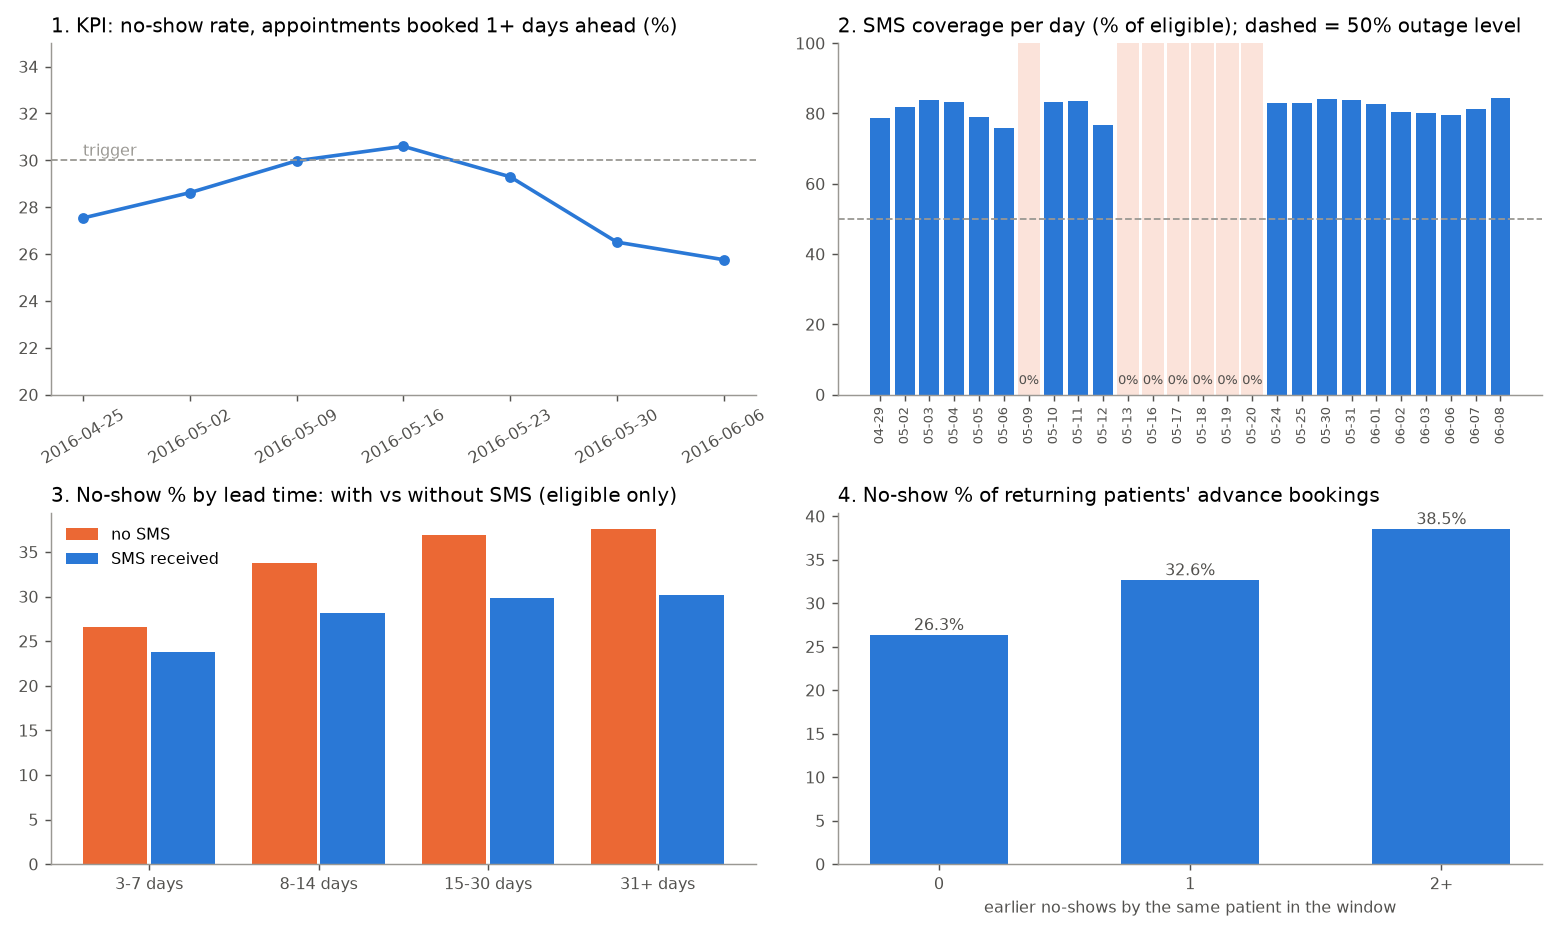

In [12]:
Image(filename=str(ROOT / 'outputs' / 'dashboard.png'))

## 6. Still unknown

- Why the SMS job sent nothing on 7 appointment days (May 9, 13, 16-20). Vendor outage, a config change, or a data export gap?
- Why May 23 and May 27 have no appointments at all. May 26 is Corpus Christi; May 27 may be a local bridge day. May 23 is not explained.
- When the SMS was sent and whether it was delivered. The source only says "received".
- Whether the patients who don't get an SMS on normal days (about 18%) have no phone number on file.
- Clinic and doctor are not in the extract, only the neighbourhood, so capacity and specialty can't be checked.

In [13]:
con.close()